# DATA ANALYSIS

## Let's see the structure of our data

In [59]:
import pandas as pd

df = pd.read_csv("./data/raw_EV_data_challenge.csv", sep=";")

for column in df[0:5].columns:
    print(f"Column: {column}, Data Type: {df[column].head(5).dtype}")
df.head()

Column: REQUEST_ID, Data Type: int64
Column: SD_CATALOG_PATH_EN, Data Type: str
Column: SUBMIT_DATE_UT, Data Type: str
Column: URGENCY_VALUE, Data Type: int64
Column: IMPACT_VALUE, Data Type: float64
Column: SLA_DELAY, Data Type: float64
Column: MAX_RESOLUTION_DATE_UT, Data Type: str
Column: END_DATE_UT, Data Type: str
Column: SUBMITTED_BY_ID, Data Type: float64
Column: nb_actions, Data Type: int64
Column: LAST_DONE_BY_ID, Data Type: float64
Column: STATUS_EN, Data Type: str
Column: REQUEST_ORIGIN, Data Type: str


,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office


## Adding target_regression

In [60]:
# Compute of the taget_value for régression
end_dt = pd.to_datetime(df['END_DATE_UT'])
submit_dt = pd.to_datetime(df['SUBMIT_DATE_UT'])

df['target_reg'] = (end_dt - submit_dt).dt.total_seconds() / 3600.0
df.head()

,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN,target_reg
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office,0.025312
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office,0.019648
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office,741.258726
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office,0.164353
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office,0.216708


# Adding Target_classification

In [61]:
end_dt = pd.to_datetime(df['END_DATE_UT'])
max_dt = pd.to_datetime(df['MAX_RESOLUTION_DATE_UT'])

# Target_classification (1 = SLA Violé, 0 = SLA Respecté)
df['target_clf'] = (end_dt > max_dt).astype(int)

df.head()

,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN,target_reg,target_clf
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office,0.025312,0
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office,0.019648,0
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office,741.258726,1
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office,0.164353,0
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office,0.216708,0


# analysis of SLA_Violation Distribution

In [62]:
print(df['target_clf'].value_counts(dropna=False))

print("\nProportion (%) :")
print(df['target_clf'].value_counts(normalize=True) * 100)

target_clf
0    49601
1    14574
Name: count, dtype: int64

Proportion (%) :
target_clf
0    77.290222
1    22.709778
Name: proportion, dtype: float64


## Effect of day, hour and minute of submittion

/tmp/ipykernel_31368/1489785343.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day'] = submit_dt.dt.dayofweek


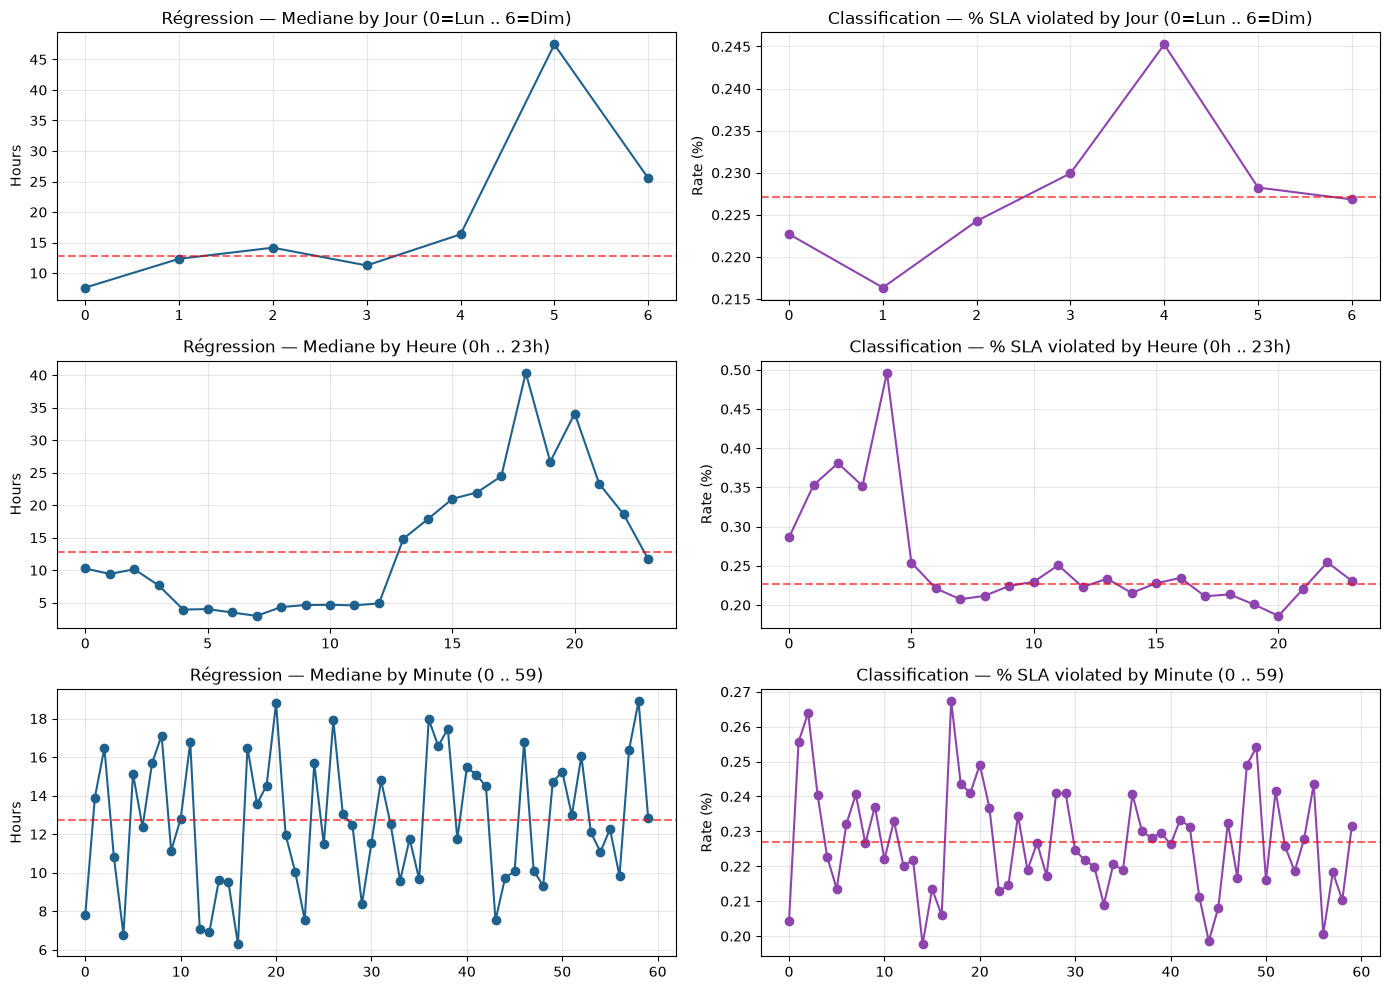

In [63]:
import matplotlib.pyplot as plt
import pandas as pd

submit_dt = pd.to_datetime(df['SUBMIT_DATE_UT'])

df['day'] = submit_dt.dt.dayofweek
df['hour'] = submit_dt.dt.hour
df['minute'] = submit_dt.dt.minute

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
features = [
    ('day', 'Jour (0=Lun .. 6=Dim)'),
    ('hour', 'Heure (0h .. 23h)'),
    ('minute', 'Minute (0 .. 59)')
]

for row, (col, label) in enumerate(features):
    # Colonne 1 : Régression -> Médiane (robust despite outliers)
    reg_median = df.groupby(col)['target_reg'].median()
    axes[row, 0].plot(reg_median.index, reg_median.values, marker='o', color='#1f618d')
    axes[row, 0].axhline(df['target_reg'].median(), color='red', linestyle='--', alpha=0.6)
    axes[row, 0].set_title(f"Régression — Mediane by {label}")
    axes[row, 0].set_ylabel("Hours")
    axes[row, 0].grid(True, alpha=0.3)

    # Colonne 2 : Classification -> Mean of 0/1 (= % de SLA violated)
    clf_rate = df.groupby(col)['target_clf'].mean()
    axes[row, 1].plot(clf_rate.index, clf_rate.values, marker='o', color='#8e44ad')
    axes[row, 1].axhline(df['target_clf'].mean(), color='red', linestyle='--', alpha=0.6)
    axes[row, 1].set_title(f"Classification — % SLA violated by {label}")
    axes[row, 1].set_ylabel("Rate (%)")
    axes[row, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("docs/Analysis/Temporal_features.pdf", dpi=300)
plt.show()

## **We check if these features are just a noise:**
We use 4 statistical tests:

#### **Kruskal-Wallis (`KRUSKAL p-val`)**
* **What it does:** Compares median resolution times across all groups (days, hours, or minutes).
* **Objective:** Check if resolution time actually changes across groups ($p < 0.05$ = signal) or stays the same ($p > 0.05$ = noise).


#### **Chi-Square (`CHI2 p-val`)**
* **What it does:** Compares SLA breach rates (`0` or `1`) across all groups.
* **Objective:** Check if SLA failure depends on the time feature ($p < 0.05$ = signal) or not ($p > 0.05$ = noise).


#### **Lag-1 Autocorrelation (`ACF(1)`)**
* **What it does:** Measures the correlation between each point $t$ and its neighbor $t+1$ on the curve.
* **Objective:** Check if the curve is smooth ($\to 1$ = real trend) or chaotic ($\approx 0$ = random noise).


#### **Spearman Stability (`2023 vs 2024`)**
* **What it does:** Compares the 2023 curve with the 2024 curve.
* **Objective:** Check if the pattern repeats over time ($\to 1$ = reliable feature) or changes randomly each year ($\approx 0$ = overfitting risk).

In [64]:
cols_to_drop = ['minute', 'submit_minute', 'day', 'hour']

df = df.drop(columns=cols_to_drop, errors='ignore')
print(df.columns.tolist())

['REQUEST_ID', 'SD_CATALOG_PATH_EN', 'SUBMIT_DATE_UT', 'URGENCY_VALUE', 'IMPACT_VALUE', 'SLA_DELAY', 'MAX_RESOLUTION_DATE_UT', 'END_DATE_UT', 'SUBMITTED_BY_ID', 'nb_actions', 'LAST_DONE_BY_ID', 'STATUS_EN', 'REQUEST_ORIGIN', 'target_reg', 'target_clf']


In [65]:
import numpy as np
import pandas as pd
from scipy import stats

submit_dt = pd.to_datetime(df['SUBMIT_DATE_UT'])

df_diag = pd.DataFrame({
    'year': submit_dt.dt.year,
    'day': submit_dt.dt.dayofweek,
    'hour': submit_dt.dt.hour,
    'minute': submit_dt.dt.minute,
    'target_reg': df['target_reg'],
    'target_clf': df['target_clf'].astype(int)
}).dropna()

df_diag = df_diag[df_diag['target_reg'] > 0]

print(f"{'FEATURE':<10} | {'KRUSKAL (Reg) p-val':<20} | {'CHI2 (Clf) p-val':<18} | {'ACF(1) Continuité':<18} | {'Stabilité 2023 vs 2024'}")
print("-" * 50)

for col in ['day', 'hour', 'minute']:
    # Kruskal-Wallis (Régression : H0 = All médianes are  équals)
    groups_reg = [group['target_reg'].values for _, group in df_diag.groupby(col)]
    _, kw_pval = stats.kruskal(*groups_reg)
    
    # Chi-2 indépendance (Classification : H0 = taux SLA indépendent from col)
    contingency = pd.crosstab(df_diag[col], df_diag['target_clf'])
    _, chi2_pval, _, _ = stats.chi2_contingency(contingency)
    
    # Autocorrélation of range 1 on médiane's curve (Continuity)
    medians = df_diag.groupby(col)['target_reg'].median()
    acf1 = medians.autocorr(lag=1)
    
    # Temporal Stabilité (Spearman's Corrélation between 2023 and 2024)
    med_2023 = df_diag[df_diag['year'] == 2023].groupby(col)['target_reg'].median()
    med_2024 = df_diag[df_diag['year'] == 2024].groupby(col)['target_reg'].median()
    common_idx = med_2023.index.intersection(med_2024.index)
    spearman_stab, _ = stats.spearmanr(med_2023.loc[common_idx], med_2024.loc[common_idx])
    
    print(f"{col:<10} | {kw_pval:<20.3e} | {chi2_pval:<18.3e} | {acf1:<18.3f} | {spearman_stab:.3f}")
df.head()

FEATURE    | KRUSKAL (Reg) p-val  | CHI2 (Clf) p-val   | ACF(1) Continuité  | Stabilité 2023 vs 2024
--------------------------------------------------


/tmp/ipykernel_31368/3641866170.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  'day': submit_dt.dt.dayofweek,


day        | 5.005e-32            | 1.726e-05          | 0.300              | 0.357
hour       | 4.422e-202           | 3.782e-51          | 0.824              | 0.888
minute     | 2.651e-01            | 4.825e-02          | 0.138              | 0.136


,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN,target_reg,target_clf
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office,0.025312,0
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office,0.019648,0
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office,741.258726,1
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office,0.164353,0
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office,0.216708,0


### **Statistical Validation of Temporal Features:**
* **submit_hour (Retained):** Exhibits extreme statistical significance ($p < 10^{-50}$), strong topological smoothness ($\text{ACF}(1) = 0.824$), and high year-over-year stability ($\rho = 0.888$).
-> It is the primary temporal driver.

* **submit_dayofweek (Retained):** Statistically significant ($p = 5.0 \times 10^{-32}$ in regression, $p = 1.7 \times 10^{-5}$ in classification), primarily driven by the weekend resolution delay. Lower rank stability ($\rho = 0.357$) reflects flat variations across Monday–Thursday.

* **submit_minute (Dropped):** Fails the Kruskal-Wallis test ($p = 0.265 > 0.05$) and shows near-zero autocorrelation ($\text{ACF}(1) = 0.138$) and inter-annual stability ($\rho = 0.136$), confirming it acts as white noise.

In [66]:
import pandas as pd

submit_dt = pd.to_datetime(df['SUBMIT_DATE_UT'])

# Hour (0 to 23)
df['submit_hour'] = submit_dt.dt.hour.astype(int)

# Day of week(0 = Monday, ..., 6 = Sunday)
df['submit_dayofweek'] = submit_dt.dt.dayofweek.astype(int)

df.head()

/tmp/ipykernel_31368/4139237733.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['submit_dayofweek'] = submit_dt.dt.dayofweek.astype(int)


,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN,target_reg,target_clf,submit_hour,submit_dayofweek
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office,0.025312,0,15,3
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office,0.019648,0,15,3
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office,741.258726,1,11,0
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office,0.164353,0,10,1
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office,0.216708,0,10,3


# **how to split data accurately:**

=== Number of tickets per day
Total number of observed days : 714
Mean per day                   : 89.9
Médiane per day                : 107.0
Standard deviation            : 61.9
Minimum (WE/fériés)           : 1
Maximum (pic)                 : 388

=== Zoom on wekdays (Monday to Friday)
Médiane by week-day        : 125.0
Mediane by enf_of_week    : 4.0

=== ESTIMATION of split size ===
1 months (~30 days)             : ~3,210 tickets
3 months (~90 days)             : ~9,630 tickets
4 months (~120 dayss)            : ~12,840 tickets
6 months (~180 days)              : ~19,260 tickets


/tmp/ipykernel_31368/253926477.py:17: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  daily_df['dayofweek'] = daily_df['date'].dt.dayofweek


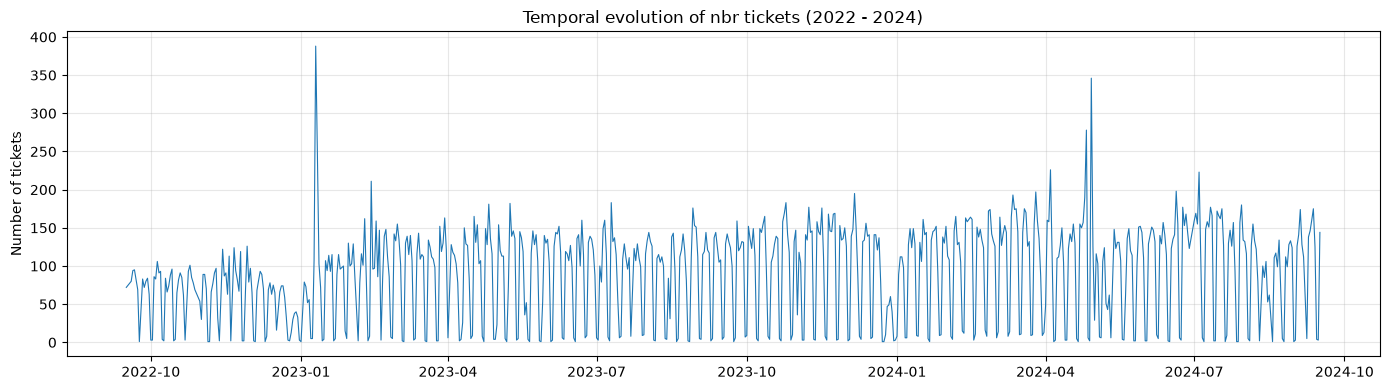

In [67]:
import matplotlib.pyplot as plt
import pandas as pd

daily_counts = submit_dt.dt.date.value_counts().sort_index()

# key statistics
print("=== Number of tickets per day")
print(f"Total number of observed days : {len(daily_counts)}")
print(f"Mean per day                   : {daily_counts.mean():.1f}")
print(f"Médiane per day                : {daily_counts.median():.1f}")
print(f"Standard deviation            : {daily_counts.std():.1f}")
print(f"Minimum (WE/fériés)           : {daily_counts.min()}")
print(f"Maximum (pic)                 : {daily_counts.max()}")

# Zoom on wekdays (Monday to Friday)
daily_df = pd.DataFrame({'date': pd.to_datetime(daily_counts.index), 'count': daily_counts.values})
daily_df['dayofweek'] = daily_df['date'].dt.dayofweek
workdays_counts = daily_df[daily_df['dayofweek'] < 5]['count']
end_week_days_counts = daily_df[daily_df['dayofweek'] >= 5]['count']

print("\n=== Zoom on wekdays (Monday to Friday)")
print(f"Médiane by week-day        : {workdays_counts.median():.1f}")
print(f"Mediane by enf_of_week    : {end_week_days_counts.median():.1f}")

# Estimating the size of splits
print("\n=== ESTIMATION of split size ===")
median_daily = daily_counts.median()
print(f"1 months (~30 days)             : ~{int(median_daily * 30):,} tickets")
print(f"3 months (~90 days)             : ~{int(median_daily * 90):,} tickets")
print(f"4 months (~120 dayss)            : ~{int(median_daily * 120):,} tickets")
print(f"6 months (~180 days)              : ~{int(median_daily * 180):,} tickets")

# Visualisation 
fig, ax1 = plt.subplots(1, 1, figsize=(14, 4))
ax1.plot(daily_counts.index, daily_counts.values, color='#1f77b4', linewidth=0.8)
ax1.set_title("Temporal evolution of nbr tickets (2022 - 2024)")
ax1.set_ylabel("Number of tickets")
ax1.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("docs/Analysis/Temporal evolution of nbr tickets.pdf", dpi=300)
plt.show()